# ColorMNIST: nuisance-corruption severity at the paper configuration

This notebook analyses three completed seeds of the severity experiment. It does not launch simulations. The configuration uses 20,000 logged observations, an autoencoder trained on those same logged images, full-sample projected-Nyström nuisances with 1,024 landmarks, and 2,000 IMQ-Euler particles per intervention arm.

CME training uses all rows, or only rows with X below 0.5, 0.25, or 0.1. Independently, inverse weights for the fixed red subgroup X >= 0.5 are multiplied by 1, 1/4, 1/20, or 1/100. The raw and mass-preserving versions are analysed separately. The latter preserves baseline empirical inverse-weight mass; neither version normalizes final signed target coefficients.

The design extends [DoubleGen, Appendix M.1.1 and Table 3](https://arxiv.org/html/2509.16842v1#A13.SS1.SSS1). Baseline means a fitted nuisance, not an oracle-correct model. These paper-configuration runs must not be pooled with the earlier pilot, which used an independent AE sample and cross-fitting.

Every reported estimate first averages the two intervention arms within a seed, then reports the mean and **sample standard deviation across three seeds**. Error bars are standard deviations, not confidence intervals. Shared plug-in/IPW flows and the baseline reused between mass controls are not additional repetitions.

In [1]:
from pathlib import Path
from itertools import product
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_SEEDS = [0, 1, 2]
CME_CUTOFFS = [1.0, 0.5, 0.25, 0.1]
WEIGHT_FACTORS = [1.0, 0.25, 0.05, 0.01]
MASS_MODES = ["raw", "preserve"]
ESTIMATORS = ["plugin", "ipw", "dr"]
RUN_DIRS = {seed: Path(f"results/severity_paper_seed{seed}") for seed in DATA_SEEDS}
SUMMARY_DIR = Path("results/severity_paper_summary")

provenances = {}
progress_rows = []
for seed, directory in RUN_DIRS.items():
    provenance_path = directory / "provenance.json"
    provenance = json.loads(provenance_path.read_text()) if provenance_path.exists() else {}
    progress_path = directory / "progress.json"
    progress = json.loads(progress_path.read_text()) if progress_path.exists() else {}
    provenances[seed] = provenance
    progress_rows.append({
        "seed": seed,
        "status": provenance.get("status", "missing"),
        "completed rows": progress.get("completed_rows", provenance.get("rows", 0)),
        "expected rows": 168,
        "completed unique flows": progress.get("completed_unique_flows", provenance.get("unique_flows", 0)),
        "expected unique flows": 78,
        "elapsed minutes": round(progress.get("elapsed_seconds", provenance.get("seconds_total", 0)) / 60, 2),
        "GPU": provenance.get("gpu", ""),
    })
progress_table = pd.DataFrame(progress_rows).set_index("seed")
display(progress_table)


,status,completed rows,expected rows,completed unique flows,expected unique flows,elapsed minutes,GPU
seed,,,,,,,
0,complete,168,168,78,78,23.39,NVIDIA L40S
1,complete,168,168,78,78,23.40,NVIDIA L40S
2,complete,168,168,78,78,23.40,NVIDIA L40S


## Validate the complete paired experiment

The progress table above is safe to inspect while jobs are running. The next cell deliberately stops until all three seeds are complete. It also rejects missing experiment cells, duplicate rows, inconsistent source hashes, or differing configurations. Only per-task data-seed lists and output locations are excluded from configuration comparison.

In [2]:
assert progress_table["status"].eq("complete").all(), (
    "All three seeds must finish before final summaries; inspect the progress table above."
)

METRICS = ["pixel_sw2_flow", "colour_w1_uniform_flow", "target_rbf_squared_distance"]
MASS_METRICS = ["sum_v", "sum_abs_v", "negative_mass", "target_colour_mean"]
KEYS = ["data_seed", "arm", "cme_cutoff", "weight_factor", "corruption_mass", "estimator"]
CELL_KEYS = ["cme_cutoff", "weight_factor", "corruption_mass", "estimator"]
weight_settings = [(1.0, "baseline")] + list(product(WEIGHT_FACTORS[1:], MASS_MODES))
expected_cells = {
    (arm, cutoff, factor, mass_mode, estimator)
    for arm, cutoff, (factor, mass_mode), estimator in product(
        [0, 1], CME_CUTOFFS, weight_settings, ESTIMATORS
    )
}

def comparable_config(configuration):
    excluded = {"data_seed", "data_seeds", "out_dir", "run_dir"}
    return {key: value for key, value in configuration.items() if key not in excluded}

base_provenance = provenances[DATA_SEEDS[0]]
base_config = comparable_config(base_provenance["config"])
base_hashes = base_provenance["source_sha256"]
assert base_hashes, "Missing implementation source hashes."
frames = []
for seed, directory in RUN_DIRS.items():
    provenance = provenances[seed]
    config = provenance["config"]
    assert provenance["data_seed"] == seed
    assert comparable_config(config) == base_config, f"Configuration mismatch at seed {seed}"
    assert provenance["source_sha256"] == base_hashes, f"Source hashes differ at seed {seed}"
    assert config["n_obs"] == 20000 and config["n_particles"] == config["n_ref"] == 2000
    assert config["n_landmarks"] == 1024 and config["cv_max_n"] == 2000
    assert config["ae_iterations"] == config["flow_iterations"] == 3000
    assert config["latent_dim"] == 32 and config["gram_ridge"] is None
    assert config["weight_threshold"] == 0.5 and not config["targets_only"]
    assert provenance["rows"] == 168 and provenance["unique_flows"] == 78
    assert provenance["sw2_dtype"] == "float32", "Paper SW2 uses float32."

    frame = pd.read_csv(directory / "results.csv")
    assert len(frame) == 168 and not frame.duplicated(KEYS).any()
    assert frame["data_seed"].eq(seed).all() and frame["repeat"].eq(0).all()
    actual = set(frame[KEYS[1:]].itertuples(index=False, name=None))
    assert actual == expected_cells, f"Missing or unexpected cells in seed {seed}"
    assert frame["shared_flow_id"].nunique() == 78
    for name, value in {
        "n_obs": 20000, "n_ae": 20000, "n_particles": 2000, "n_ref": 2000,
        "dr_fit": "nosplit", "ae_split": "none", "solver": "projected_nystrom",
        "n_landmarks": 1024, "weight_threshold": 0.5,
    }.items():
        assert frame[name].eq(value).all(), f"Inconsistent {name} in seed {seed}"
    assert np.isfinite(frame[METRICS + MASS_METRICS].to_numpy()).all()
    assert (frame[METRICS].to_numpy() >= -1e-10).all()
    for _, shared in frame.groupby("shared_flow_id"):
        assert np.allclose(shared[METRICS + MASS_METRICS].to_numpy(),
                           shared[METRICS + MASS_METRICS].iloc[0].to_numpy(),
                           rtol=1e-11, atol=1e-12), "Shared target/flow rows disagree."
    frames.append(frame)

results = pd.concat(frames, ignore_index=True)
assert len(results) == 504
display(pd.Series({
    "independent data seeds": len(DATA_SEEDS),
    "total configuration rows": len(results),
    "total unique flows": results["shared_flow_id"].nunique(),
    "matched source files": len(base_hashes),
    "aggregation": "average both arms within seed, then mean and sample SD across seeds",
}, name="Validated experiment"))


independent data seeds                                                      3
total configuration rows                                                  504
total unique flows                                                        234
matched source files                                                       10
aggregation                 average both arms within seed, then mean and s...
Name: Validated experiment, dtype: object

## Aggregate arms within each seed

The exported main summary keeps the baseline weight setting once, under mass mode `baseline`. For comparison tables and figures only, that same estimate is displayed in both the raw and mass-preserving panels. Its reuse does not increase the sample size.

In [3]:
group_keys = ["data_seed"] + CELL_KEYS
arm_counts = results.groupby(group_keys)["arm"].nunique()
assert arm_counts.eq(2).all(), "Each seed/cell must contain both intervention arms."
within_seed = results.groupby(group_keys, sort=False)[METRICS + MASS_METRICS].mean().reset_index()
summary = within_seed.groupby(CELL_KEYS, sort=False)[METRICS + MASS_METRICS].agg(["mean", "std"])
summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
summary["n_seeds"] = within_seed.groupby(CELL_KEYS)["data_seed"].nunique()
assert summary["n_seeds"].eq(3).all()
summary = summary.reset_index()

# Display the same baseline in both panels without re-estimating its uncertainty.
expanded_frames = []
for mass_mode in MASS_MODES:
    panel = summary[summary["corruption_mass"].isin(["baseline", mass_mode])].copy()
    panel["corruption_mass"] = mass_mode
    expanded_frames.append(panel)
plot_summary = pd.concat(expanded_frames, ignore_index=True)
assert not plot_summary.duplicated(CELL_KEYS).any()

SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
within_seed.to_csv(SUMMARY_DIR / "arm_averages_by_seed.csv", index=False)
summary.to_csv(SUMMARY_DIR / "severity_mean_sd.csv", index=False)
plot_summary.to_csv(SUMMARY_DIR / "severity_plot_mean_sd.csv", index=False)
(SUMMARY_DIR / "analysis_provenance.json").write_text(json.dumps({
    "data_seeds": DATA_SEEDS,
    "source_runs": {str(seed): str(directory) for seed, directory in RUN_DIRS.items()},
    "source_sha256": base_hashes,
    "common_config": base_config,
    "aggregation": "equal arm mean within seed, then mean and sample standard deviation (ddof=1)",
    "baseline_reuse": "one baseline estimate displayed in both mass-control panels",
}, indent=2) + "\n")

metric_labels = {
    "pixel_sw2_flow": "Final pixel SW2",
    "colour_w1_uniform_flow": "Final colour W1 to Uniform[0,1]",
    "target_rbf_squared_distance": "Target RBF squared error",
}
estimator_labels = {"plugin": "Plug-in", "ipw": "IPW", "dr": "DR"}
cutoff_labels = {1.0: "Full CME", 0.5: "CME: X < 0.5", 0.25: "CME: X < 0.25", 0.1: "CME: X < 0.1"}

for metric in METRICS:
    for mass_mode in MASS_MODES:
        panel = plot_summary[plot_summary["corruption_mass"].eq(mass_mode)].copy()
        panel["mean ± SD"] = panel.apply(
            lambda row: f'{row[f"{metric}_mean"]:.6f} ± {row[f"{metric}_std"]:.6f}', axis=1
        )
        table = panel.pivot(index=["cme_cutoff", "weight_factor"],
                            columns="estimator", values="mean ± SD")
        table = table.reindex(pd.MultiIndex.from_product(
            [CME_CUTOFFS, WEIGHT_FACTORS], names=["cme_cutoff", "weight_factor"]
        ))[ESTIMATORS].rename(columns=estimator_labels)
        display(Markdown(f"**{metric_labels[metric]} — {mass_mode} weight corruption; mean ± sample SD, n=3 seeds**"))
        display(table)


**Final pixel SW2 — raw weight corruption; mean ± sample SD, n=3 seeds**

estimator                             Plug-in                  IPW  \
cme_cutoff weight_factor                                             
1.00       1.00           0.009413 ± 0.000576  0.009486 ± 0.000350   
           0.25           0.009413 ± 0.000576  0.033420 ± 0.000784   
           0.05           0.009413 ± 0.000576  0.041288 ± 0.001207   
           0.01           0.009413 ± 0.000576  0.042811 ± 0.001288   
0.50       1.00           0.027154 ± 0.000895  0.009486 ± 0.000350   
           0.25           0.027154 ± 0.000895  0.033420 ± 0.000784   
           0.05           0.027154 ± 0.000895  0.041288 ± 0.001207   
           0.01           0.027154 ± 0.000895  0.042811 ± 0.001288   
0.25       1.00           0.067196 ± 0.040217  0.009486 ± 0.000350   
           0.25           0.067196 ± 0.040217  0.033420 ± 0.000784   
           0.05           0.067196 ± 0.040217  0.041288 ± 0.001207   
           0.01           0.067196 ± 0.040217  0.042811 ± 0.001288   
0.10       1.00           0.086038 ± 0.057141  0.009486 ± 0.000350   
           0.25           0.086038 ± 0.057141  0.033420 ± 0.000784   
           0.05           0.086038 ± 0.057141  0.041288 ± 0.001207   
           0.01           0.086038 ± 0.057141  0.042811 ± 0.001288   

estimator                                  DR  
cme_cutoff weight_factor                       
1.00       1.00           0.009402 ± 0.000561  
           0.25           0.009416 ± 0.000575  
           0.05           0.009422 ± 0.000578  
           0.01           0.009423 ± 0.000578  
0.50       1.00           0.009464 ± 0.000459  
           0.25           0.021579 ± 0.000690  
           0.05           0.026112 ± 0.000876  
           0.01           0.027005 ± 0.000924  
0.25       1.00           0.009434 ± 0.000474  
           0.25           0.046130 ± 0.027043  
           0.05           0.054880 ± 0.029788  
           0.01           0.056517 ± 0.030231  
0.10       1.00           0.009581 ± 0.000485  
           0.25           0.041199 ± 0.015664  
           0.05           0.050020 ± 0.018035  
           0.01           0.051653 ± 0.018377

**Final pixel SW2 — preserve weight corruption; mean ± sample SD, n=3 seeds**

estimator                             Plug-in                  IPW  \
cme_cutoff weight_factor                                             
1.00       1.00           0.009413 ± 0.000576  0.009486 ± 0.000350   
           0.25           0.009413 ± 0.000576  0.028982 ± 0.001461   
           0.05           0.009413 ± 0.000576  0.043214 ± 0.000928   
           0.01           0.009413 ± 0.000576  0.046735 ± 0.000781   
0.50       1.00           0.027154 ± 0.000895  0.009486 ± 0.000350   
           0.25           0.027154 ± 0.000895  0.028982 ± 0.001461   
           0.05           0.027154 ± 0.000895  0.043214 ± 0.000928   
           0.01           0.027154 ± 0.000895  0.046735 ± 0.000781   
0.25       1.00           0.067196 ± 0.040217  0.009486 ± 0.000350   
           0.25           0.067196 ± 0.040217  0.028982 ± 0.001461   
           0.05           0.067196 ± 0.040217  0.043214 ± 0.000928   
           0.01           0.067196 ± 0.040217  0.046735 ± 0.000781   
0.10       1.00           0.086038 ± 0.057141  0.009486 ± 0.000350   
           0.25           0.086038 ± 0.057141  0.028982 ± 0.001461   
           0.05           0.086038 ± 0.057141  0.043214 ± 0.000928   
           0.01           0.086038 ± 0.057141  0.046735 ± 0.000781   

estimator                                  DR  
cme_cutoff weight_factor                       
1.00       1.00           0.009402 ± 0.000561  
           0.25           0.009429 ± 0.000566  
           0.05           0.009449 ± 0.000565  
           0.01           0.009455 ± 0.000564  
0.50       1.00           0.009464 ± 0.000459  
           0.25           0.018214 ± 0.000696  
           0.05           0.025206 ± 0.000916  
           0.01           0.026928 ± 0.001042  
0.25       1.00           0.009434 ± 0.000474  
           0.25           0.031981 ± 0.016294  
           0.05           0.043888 ± 0.019774  
           0.01           0.046550 ± 0.020311  
0.10       1.00           0.009581 ± 0.000485  
           0.25           0.033945 ± 0.021071  
           0.05           0.047380 ± 0.029467  
           0.01           0.050351 ± 0.031094

**Final colour W1 to Uniform[0,1] — raw weight corruption; mean ± sample SD, n=3 seeds**

estimator                             Plug-in                  IPW  \
cme_cutoff weight_factor                                             
1.00       1.00           0.017020 ± 0.003250  0.020318 ± 0.004140   
           0.25           0.017020 ± 0.003250  0.071493 ± 0.007599   
           0.05           0.017020 ± 0.003250  0.084528 ± 0.009173   
           0.01           0.017020 ± 0.003250  0.086313 ± 0.009481   
0.50       1.00           0.092467 ± 0.001907  0.020318 ± 0.004140   
           0.25           0.092467 ± 0.001907  0.071493 ± 0.007599   
           0.05           0.092467 ± 0.001907  0.084528 ± 0.009173   
           0.01           0.092467 ± 0.001907  0.086313 ± 0.009481   
0.25       1.00           0.163647 ± 0.112419  0.020318 ± 0.004140   
           0.25           0.163647 ± 0.112419  0.071493 ± 0.007599   
           0.05           0.163647 ± 0.112419  0.084528 ± 0.009173   
           0.01           0.163647 ± 0.112419  0.086313 ± 0.009481   
0.10       1.00           0.172949 ± 0.195791  0.020318 ± 0.004140   
           0.25           0.172949 ± 0.195791  0.071493 ± 0.007599   
           0.05           0.172949 ± 0.195791  0.084528 ± 0.009173   
           0.01           0.172949 ± 0.195791  0.086313 ± 0.009481   

estimator                                  DR  
cme_cutoff weight_factor                       
1.00       1.00           0.016235 ± 0.003381  
           0.25           0.016347 ± 0.003331  
           0.05           0.016383 ± 0.003318  
           0.01           0.016391 ± 0.003315  
0.50       1.00           0.016794 ± 0.002414  
           0.25           0.071823 ± 0.000251  
           0.05           0.090047 ± 0.001226  
           0.01           0.093627 ± 0.001385  
0.25       1.00           0.016314 ± 0.002853  
           0.25           0.119589 ± 0.064585  
           0.05           0.145538 ± 0.078315  
           0.01           0.149930 ± 0.080750  
0.10       1.00           0.016454 ± 0.003342  
           0.25           0.099384 ± 0.042699  
           0.05           0.121800 ± 0.057958  
           0.01           0.125399 ± 0.060847

... (2 outputs left out)

**Target RBF squared error — raw weight corruption; mean ± sample SD, n=3 seeds**

estimator                             Plug-in                  IPW  \
cme_cutoff weight_factor                                             
1.00       1.00           0.000539 ± 0.000060  0.000700 ± 0.000133   
           0.25           0.000539 ± 0.000060  0.077060 ± 0.003034   
           0.05           0.000539 ± 0.000060  0.122015 ± 0.004932   
           0.01           0.000539 ± 0.000060  0.132249 ± 0.005371   
0.50       1.00           0.038995 ± 0.006689  0.000700 ± 0.000133   
           0.25           0.038995 ± 0.006689  0.077060 ± 0.003034   
           0.05           0.038995 ± 0.006689  0.122015 ± 0.004932   
           0.01           0.038995 ± 0.006689  0.132249 ± 0.005371   
0.25       1.00           0.912140 ± 1.342359  0.000700 ± 0.000133   
           0.25           0.912140 ± 1.342359  0.077060 ± 0.003034   
           0.05           0.912140 ± 1.342359  0.122015 ± 0.004932   
           0.01           0.912140 ± 1.342359  0.132249 ± 0.005371   
0.10       1.00           1.922187 ± 2.924024  0.000700 ± 0.000133   
           0.25           1.922187 ± 2.924024  0.077060 ± 0.003034   
           0.05           1.922187 ± 2.924024  0.122015 ± 0.004932   
           0.01           1.922187 ± 2.924024  0.132249 ± 0.005371   

estimator                                  DR  
cme_cutoff weight_factor                       
1.00       1.00           0.000547 ± 0.000055  
           0.25           0.000559 ± 0.000061  
           0.05           0.000564 ± 0.000062  
           0.01           0.000565 ± 0.000063  
0.50       1.00           0.000573 ± 0.000045  
           0.25           0.021864 ± 0.002794  
           0.05           0.034627 ± 0.005040  
           0.01           0.037538 ± 0.005566  
0.25       1.00           0.000590 ± 0.000042  
           0.25           0.298620 ± 0.413714  
           0.05           0.478366 ± 0.663043  
           0.01           0.519382 ± 0.719933  
0.10       1.00           0.000836 ± 0.000422  
           0.25           0.149513 ± 0.135550  
           0.05           0.236916 ± 0.213404  
           0.01           0.256809 ± 0.231088

**Target RBF squared error — preserve weight corruption; mean ± sample SD, n=3 seeds**

estimator                             Plug-in                  IPW  \
cme_cutoff weight_factor                                             
1.00       1.00           0.000539 ± 0.000060  0.000700 ± 0.000133   
           0.25           0.000539 ± 0.000060  0.018235 ± 0.002035   
           0.05           0.000539 ± 0.000060  0.040216 ± 0.002500   
           0.01           0.000539 ± 0.000060  0.047031 ± 0.002514   
0.50       1.00           0.038995 ± 0.006689  0.000700 ± 0.000133   
           0.25           0.038995 ± 0.006689  0.018235 ± 0.002035   
           0.05           0.038995 ± 0.006689  0.040216 ± 0.002500   
           0.01           0.038995 ± 0.006689  0.047031 ± 0.002514   
0.25       1.00           0.912140 ± 1.342359  0.000700 ± 0.000133   
           0.25           0.912140 ± 1.342359  0.018235 ± 0.002035   
           0.05           0.912140 ± 1.342359  0.040216 ± 0.002500   
           0.01           0.912140 ± 1.342359  0.047031 ± 0.002514   
0.10       1.00           1.922187 ± 2.924024  0.000700 ± 0.000133   
           0.25           1.922187 ± 2.924024  0.018235 ± 0.002035   
           0.05           1.922187 ± 2.924024  0.040216 ± 0.002500   
           0.01           1.922187 ± 2.924024  0.047031 ± 0.002514   

estimator                                  DR  
cme_cutoff weight_factor                       
1.00       1.00           0.000547 ± 0.000055  
           0.25           0.000580 ± 0.000058  
           0.05           0.000603 ± 0.000060  
           0.01           0.000609 ± 0.000061  
0.50       1.00           0.000573 ± 0.000045  
           0.25           0.014000 ± 0.001143  
           0.05           0.030974 ± 0.003753  
           0.01           0.036243 ± 0.004652  
0.25       1.00           0.000590 ± 0.000042  
           0.25           0.098168 ± 0.119960  
           0.05           0.221005 ± 0.269537  
           0.01           0.258960 ± 0.315580  
0.10       1.00           0.000836 ± 0.000422  
           0.25           0.150637 ± 0.223768  
           0.05           0.352093 ± 0.526970  
           0.01           0.415322 ± 0.622297

## Mass, training coverage and shared controls

Restricting the CME can leave very few examples from the rarer treatment arm. The table reports the actual number of target-arm training observations and landmarks, not only the nominal cutoff. Signed-target mass, absolute mass, negative mass and selected colour moments are exported with the full summaries.

The raw and mass-preserving weight settings retain the same relative subgroup distortion. The latter preserves each arm's baseline empirical weight mass, which is not necessarily one. Raw signed target moments and moments divided by mass are diagnostics; they need not be moments of a probability law.

The independent oracle and decoder-roundtrip rows are comparison levels, not mathematical lower bounds. The oracle–oracle RBF comparison uses two samples of size 2,000, whereas the fitted target is constructed from 20,000 logged observations.

In [4]:
fit_keys = ["data_seed", "arm", "cme_cutoff"]
fit_columns = ["n_cme_train", "n_cme_train_arm", "n_landmarks_arm", "gram_ridge"]
assert results.groupby(fit_keys)[fit_columns].nunique().le(1).all().all()
fit_diagnostics = results[fit_keys + fit_columns].drop_duplicates().sort_values(
    ["data_seed", "arm", "cme_cutoff"], ascending=[True, True, False]
)
assert len(fit_diagnostics) == 24
assert (fit_diagnostics[["n_cme_train", "n_cme_train_arm"]] > 0).all().all()
assert fit_diagnostics["n_landmarks_arm"].ge(0).all()
fit_diagnostics.to_csv(SUMMARY_DIR / "cme_training_counts.csv", index=False)
display(Markdown("**Actual training support and target-arm coverage, by seed**"))
display(fit_diagnostics.set_index(fit_keys))

weight_keys = ["data_seed", "arm", "weight_factor", "corruption_mass"]
weight_columns = ["weight_mass", "baseline_weight_mass", "weight_ess", "weight_max"]
assert results.groupby(weight_keys)[weight_columns].nunique().le(1).all().all()
weight_diagnostics = results[weight_keys + weight_columns].drop_duplicates().sort_values(weight_keys)
preserved = weight_diagnostics["corruption_mass"].eq("preserve")
assert np.allclose(weight_diagnostics.loc[preserved, "weight_mass"],
                   weight_diagnostics.loc[preserved, "baseline_weight_mass"],
                   rtol=1e-10, atol=1e-12)
weight_diagnostics.to_csv(SUMMARY_DIR / "inverse_weight_diagnostics.csv", index=False)
display(Markdown("**Inverse-weight mass, ESS and maximum, by seed and arm**"))
display(weight_diagnostics.set_index(weight_keys).round(5))

control_columns = [
    f"{metric}_{stage}"
    for stage in ["initial", "floor", "roundtrip_floor"]
    for metric in ["pixel_sw2", "colour_w1_uniform"]
] + ["target_rbf_oracle_floor"]
assert results.groupby(["data_seed", "arm"])[control_columns].nunique().le(1).all().all()
controls_by_seed = (
    results.drop_duplicates(["data_seed", "arm"])
    .groupby("data_seed")[control_columns].mean()
)
controls_summary = controls_by_seed.agg(["mean", "std"]).T
controls_by_seed.to_csv(SUMMARY_DIR / "shared_controls_by_seed.csv")
controls_summary.to_csv(SUMMARY_DIR / "shared_controls_mean_sd.csv")
display(Markdown("**Shared controls — arms averaged within seed, then mean ± sample SD across three seeds**"))
display(controls_summary.style.format("{:.6f}"))

for mass_mode in MASS_MODES:
    dr = plot_summary[(plot_summary["corruption_mass"] == mass_mode)
                      & (plot_summary["estimator"] == "dr")]
    diagnostics = dr.set_index(["cme_cutoff", "weight_factor"])[
        ["sum_v_mean", "sum_v_std", "negative_mass_mean", "negative_mass_std"]
    ].reindex(pd.MultiIndex.from_product(
        [CME_CUTOFFS, WEIGHT_FACTORS], names=["cme_cutoff", "weight_factor"]
    ))
    display(Markdown(f"**DR target mass and negative mass — {mass_mode} corruption**"))
    display(diagnostics.style.format("{:.6f}"))


**Actual training support and target-arm coverage, by seed**

n_cme_train  n_cme_train_arm  n_landmarks_arm  \
data_seed arm cme_cutoff                                                  
0         0   1.00              20000            10077              503   
              0.50              10076             8760              881   
              0.25               5058             4928              995   
              0.10               2023             2007             1016   
          1   1.00              20000             9923              521   
              0.50              10076             1316              143   
              0.25               5058              130               29   
              0.10               2023               16                8   
1         0   1.00              20000            10020              506   
              0.50              10077             8644              873   
              0.25               5026             4870              996   
              0.10               2009             1974             1006   
          1   1.00              20000             9980              518   
              0.50              10077             1433              151   
              0.25               5026              156               28   
              0.10               2009               35               18   
2         0   1.00              20000             9968              496   
              0.50              10035             8636              870   
              0.25               4989             4852              996   
              0.10               1974             1952             1011   
          1   1.00              20000            10032              528   
              0.50              10035             1399              154   
              0.25               4989              137               28   
              0.10               1974               22               13   

                          gram_ridge  
data_seed arm cme_cutoff              
0         0   1.00            1.0000  
              0.50           10.0000  
              0.25            1.0000  
              0.10            1.0000  
          1   1.00            1.0000  
              0.50           10.0000  
              0.25            1.0000  
              0.10            1.0000  
1         0   1.00            0.1000  
              0.50            1.0000  
              0.25            0.0010  
              0.10            1.0000  
          1   1.00            0.1000  
              0.50            1.0000  
              0.25            0.0010  
              0.10            1.0000  
2         0   1.00            1.0000  
              0.50            1.0000  
              0.25            1.0000  
              0.10            0.0001  
          1   1.00            1.0000  
              0.50            1.0000  
              0.25            1.0000  
              0.10            0.0001

**Inverse-weight mass, ESS and maximum, by seed and arm**

weight_mass  \
data_seed arm weight_factor corruption_mass                
0         0   0.01          preserve             1.01638   
                            raw                  0.51104   
              0.05          preserve             1.01638   
                            raw                  0.53146   
              0.25          preserve             1.01638   
                            raw                  0.63355   
              1.00          baseline             1.01638   
          1   0.01          preserve             0.96088   
                            raw                  0.46704   
              0.05          preserve             0.96088   
                            raw                  0.48699   
              0.25          preserve             0.96088   
                            raw                  0.58676   
              1.00          baseline             0.96088   
1         0   0.01          preserve             0.99155   
                            raw                  0.50910   
              0.05          preserve             0.99155   
                            raw                  0.52860   
              0.25          preserve             0.99155   
                            raw                  0.62606   
              1.00          baseline             0.99155   
          1   0.01          preserve             0.99673   
                            raw                  0.50484   
              0.05          preserve             0.99673   
                            raw                  0.52471   
              0.25          preserve             0.99673   
                            raw                  0.62408   
              1.00          baseline             0.99673   
2         0   0.01          preserve             0.99035   
                            raw                  0.50830   
              0.05          preserve             0.99035   
                            raw                  0.52778   
              0.25          preserve             0.99035   
                            raw                  0.62516   
              1.00          baseline             0.99035   
          1   0.01          preserve             0.97844   
                            raw                  0.48385   
              0.05          preserve             0.97844   
                            raw                  0.50383   
              0.25          preserve             0.97844   
                            raw                  0.60375   
              1.00          baseline             0.97844   

                                             baseline_weight_mass  weight_ess  \
data_seed arm weight_factor corruption_mass                                     
0         0   0.01          preserve                      1.01638  8634.40240   
                            raw                           1.01638  8634.40240   
              0.05          preserve                      1.01638  8752.59906   
                            raw                           1.01638  8752.59906   
              0.25          preserve                      1.01638  4844.32594   
                            raw                           1.01638  4844.32594   
              1.00          baseline                      1.01638  1182.95056   
          1   0.01          preserve                      0.96088   344.42562   
                            raw                           0.96088   344.42562   
              0.05          preserve                      0.96088   374.44152   
                            raw                           0.96088   374.44152   
              0.25          preserve                      0.96088   542.03831   
                            raw                           0.96088   542.03831   
              1.00          baseline                      0.96088  1392.17353   
1         0   0.01          preserve                      0.99155  8496.05883   
                           

**Shared controls — arms averaged within seed, then mean ± sample SD across three seeds**

,mean,std
pixel_sw2_initial,0.043365,0.000080
colour_w1_uniform_initial,0.222877,0.003244
pixel_sw2_floor,0.006303,0.000323
colour_w1_uniform_floor,0.006298,0.001915
pixel_sw2_roundtrip_floor,0.008192,0.000887
colour_w1_uniform_roundtrip_floor,0.014868,0.001924
target_rbf_oracle_floor,0.000421,0.000130


**DR target mass and negative mass — raw corruption**

**DR target mass and negative mass — preserve corruption**

## Severity curves

Each column fixes the CME training restriction. Moving left to right within a panel strengthens the inverse-weight corruption. The two rows separate raw and mass-preserving corruption. Curves compare plug-in, IPW and DR under paired data and sampler settings.

Error bars are sample standard deviations across the three independent seed averages. Shared plug-in/IPW controls are deliberately repeated across panels. Dashed lines show the mean independent-oracle comparison, with the sample-size distinction above applying to target RBF error.

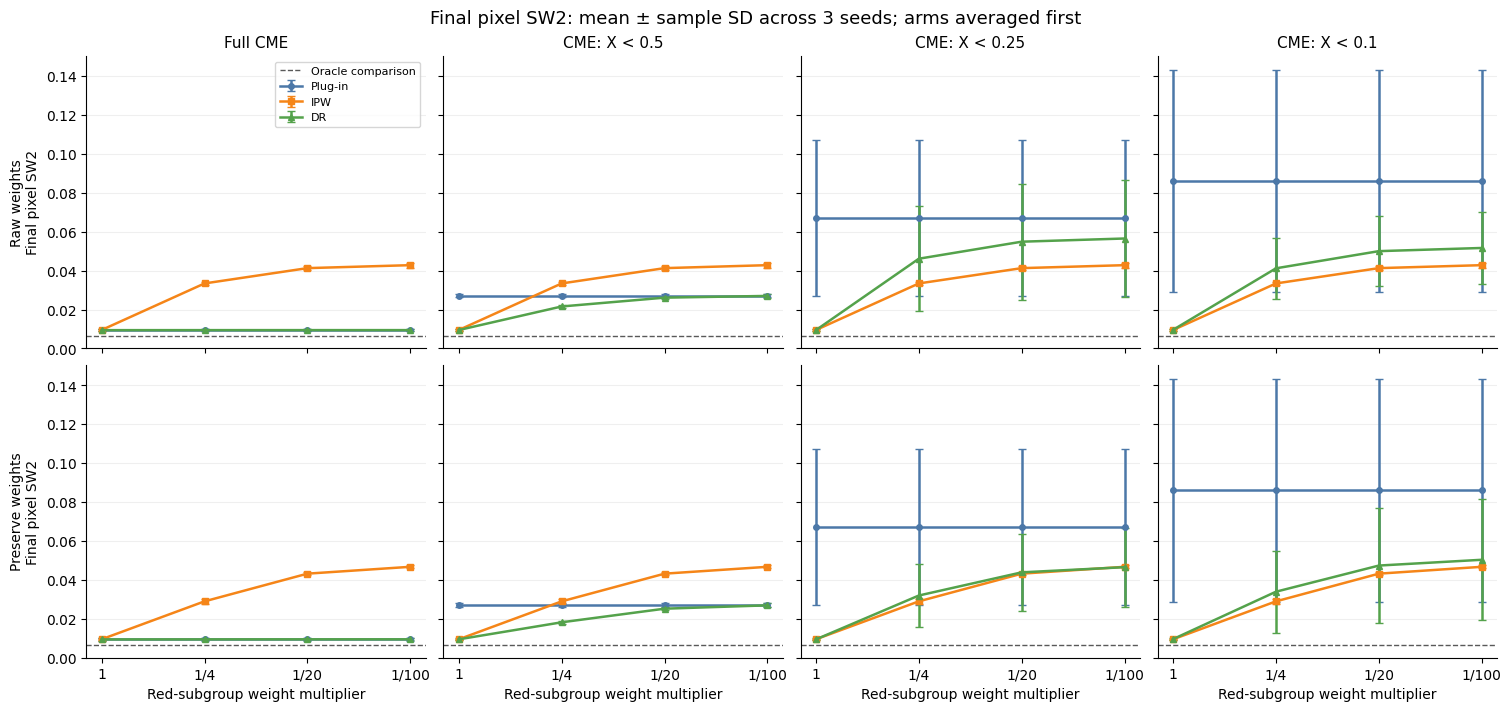

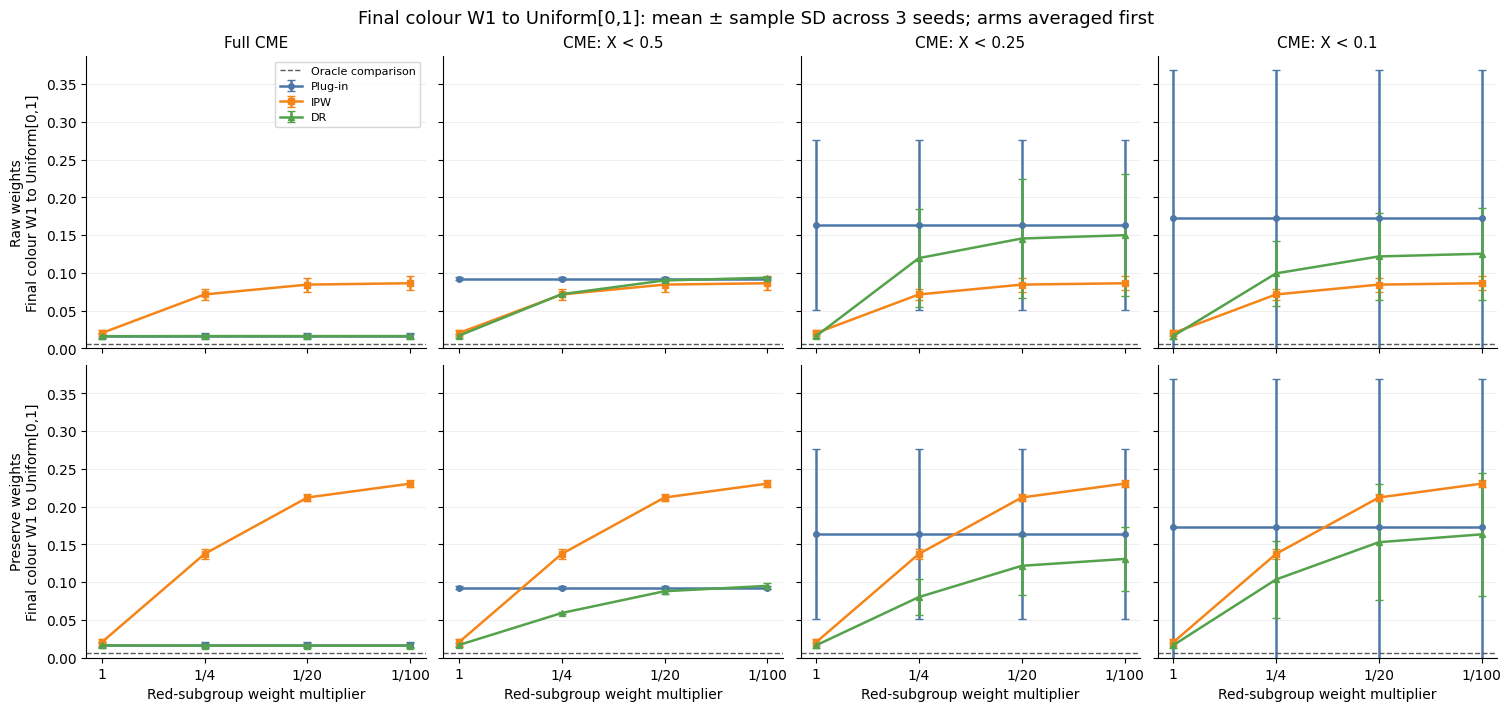

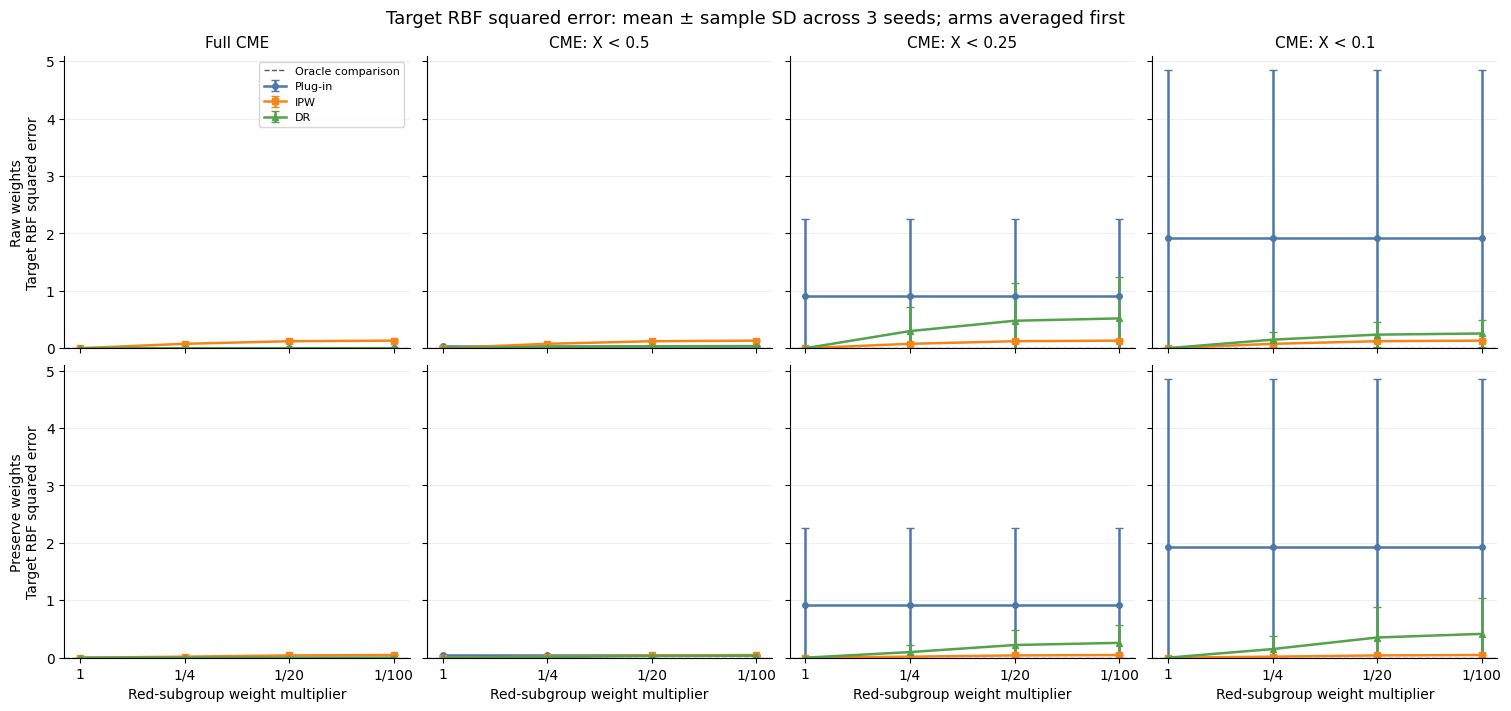

**Exported analysis:** pixel_sw2_flow_severity.png, colour_w1_uniform_flow_severity.png, target_rbf_squared_distance_severity.png

In [5]:
colours = {"plugin": "#4c78a8", "ipw": "#f58518", "dr": "#54a24b"}
markers = {"plugin": "o", "ipw": "s", "dr": "^"}
comparison_columns = {
    "pixel_sw2_flow": "pixel_sw2_floor",
    "colour_w1_uniform_flow": "colour_w1_uniform_floor",
    "target_rbf_squared_distance": "target_rbf_oracle_floor",
}
positions = np.arange(len(WEIGHT_FACTORS))
plot_files = []
for metric in METRICS:
    fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True,
                             constrained_layout=True)
    for row_index, mass_mode in enumerate(MASS_MODES):
        for column_index, cutoff in enumerate(CME_CUTOFFS):
            ax = axes[row_index, column_index]
            cell = plot_summary[(plot_summary["corruption_mass"] == mass_mode)
                                & (plot_summary["cme_cutoff"] == cutoff)]
            for estimator in ESTIMATORS:
                curve = cell[cell["estimator"] == estimator].set_index("weight_factor").reindex(WEIGHT_FACTORS)
                assert len(curve) == 4 and curve["n_seeds"].eq(3).all()
                ax.errorbar(positions, curve[f"{metric}_mean"],
                            yerr=curve[f"{metric}_std"], label=estimator_labels[estimator],
                            color=colours[estimator], marker=markers[estimator],
                            linewidth=1.8, markersize=4, capsize=3)
            comparison = controls_summary.loc[comparison_columns[metric], "mean"]
            ax.axhline(comparison, color="0.35", linestyle="--", linewidth=1,
                       label="Oracle comparison")
            if row_index == 0:
                ax.set_title(cutoff_labels[cutoff], fontsize=11)
            if column_index == 0:
                ax.set_ylabel(f"{mass_mode.capitalize()} weights\n{metric_labels[metric]}")
            if row_index == 1:
                ax.set_xlabel("Red-subgroup weight multiplier")
            ax.set_xticks(positions, ["1", "1/4", "1/20", "1/100"])
            ax.grid(axis="y", alpha=0.2)
            ax.spines[["top", "right"]].set_visible(False)
    # Set shared limits after every panel has contributed its data. Setting
    # a limit inside the loop disables autoscaling before severe cases arrive.
    upper = max((plot_summary[f"{metric}_mean"]
                 + plot_summary[f"{metric}_std"]).max(), comparison)
    axes[0, 0].set_ylim(0, 1.05 * upper)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f"{metric_labels[metric]}: mean ± sample SD across 3 seeds; arms averaged first",
                 fontsize=13)
    output = SUMMARY_DIR / f"{metric}_severity.png"
    fig.savefig(output, dpi=180, bbox_inches="tight")
    plot_files.append(str(output))
    plt.show()

display(Markdown("**Exported analysis:** " + ", ".join(Path(path).name for path in plot_files)))


## Interpretation boundaries

Look for preservation of target accuracy and final sample quality when either nuisance remains adequate. Increasing the CME restriction or reducing the weight multiplier is a prespecified increase in corruption severity; finite-sample errors need not change monotonically at every step. The both-corrupted region has no generic DR consistency guarantee.

The paper configuration reuses observations for the autoencoder and nuisance fits. These results therefore do not inherit an independent-nuisance argument from the earlier cross-fitted pilot. Three seeds provide a small reproducibility check, not precise uncertainty estimation. Inspect per-seed training coverage, signed mass and the mass-preserving control before attributing a deterioration entirely to the colour distribution.